<a href="https://colab.research.google.com/github/Leenasai15/Movie-audience-interest-prediction/blob/main/Capstone_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Movie Audience Interest Prediction
**Pipeline:** Cleaning → VADER sentiment (real reviews only) → Movie-level aggregation → Merge → Normalization → Audience Interest Score → Categories → ML → Export

> Only movies that have **actual user reviews** are used for sentiment, scoring and ML. Movies without reviews are excluded (no fake / filled sentiment).

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Importing libraries

In [ ]:
import os, re, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
nltk.download('vader_lexicon', quiet=True)
from nltk.sentiment.vader import SentimentIntensityAnalyzer

from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report)

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
RANDOM_STATE = 42
OUT_DIR = 'outputs'
os.makedirs(OUT_DIR, exist_ok=True)
print('Libraries imported')

Libraries imported


## 2. Loading datasets


In [ ]:
DATA_DIR = 'data'
os.makedirs(DATA_DIR, exist_ok=True)

if not (os.path.exists(f'{DATA_DIR}/movies.csv') and os.path.exists(f'{DATA_DIR}/reviews.csv')):
    from google.colab import files
    uploaded = files.upload()                       # choose the dataset .zip
    for fname in uploaded:
        if fname.lower().endswith('.zip'):
            with zipfile.ZipFile(fname) as z:
                z.extractall(DATA_DIR)

# engine='python' is needed because a few text fields contain line breaks / broken rows
movies  = pd.read_csv(f'{DATA_DIR}/movies.csv', engine='python')
reviews = pd.read_csv(f'{DATA_DIR}/reviews.csv')

print('movies  :', movies.shape)
print('reviews :', reviews.shape)
print('Movies that have at least one review:', reviews['movie_id'].nunique())
movies.head(3)

movies  : (9771, 22)
reviews : (13073, 13)
Movies that have at least one review: 3752


,id,title,original_title,overview,release_date,runtime,budget,revenue,vote_average,vote_count,...,backdrop_path,status,tagline,homepage,original_language,adult,video,created_at,updated_at,genres
0,2,Ariel,Ariel,A Finnish man goes to the city to find a job a...,1988-10-21,73.0,0.0,0.0,7.102,368,...,/hQ4pYsIbP22TMXOUdSfC2mjWrO0.jpg,Released,NaN,NaN,fi,0,0,2026-02-13 12:09:05,2026-02-13T17:39:05.734678,"Drama,Comedy,Crime,Romance"
1,11,Star Wars,Star Wars,Princess Leia is captured and held hostage by ...,1977-05-25,121.0,11000000.0,775398007.0,8.202,21922,...,/2w4xG178RpB4MDAIfTkqAuSJzec.jpg,Released,"A long time ago in a galaxy far, far away...",http://www.starwars.com/films/star-wars-episod...,en,0,0,2026-02-13 10:49:07,2026-02-13T16:19:07.277805,"Adventure,Action,Science Fiction"
2,12,Finding Nemo,Finding Nemo,"Nemo, an adventurous young clownfish, is unexp...",2003-05-30,100.0,94000000.0,940335536.0,7.817,20256,...,/eCynaAOgYYiw5yN5lBwz3IxqvaW.jpg,Released,There are 3.7 trillion fish in the ocean. They...,http://movies.disney.com/finding-nemo,en,0,0,2026-02-13 10:52:41,2026-02-13T16:22:41.330322,"Animation,Family"


## 3. Data cleaning

In [ ]:
print('--- MOVIES: missing values (top) ---')
print(movies.isnull().sum().sort_values(ascending=False).head(8))
print('\nDuplicate rows   :', movies.duplicated().sum())
print('Duplicate ids    :', movies['id'].duplicated().sum())
print('\n--- REVIEWS: missing values ---')
print(reviews.isnull().sum()[reviews.isnull().sum() > 0])
print('Duplicate rows   :', reviews.duplicated().sum())
print('Duplicate content:', reviews.duplicated(subset=['movie_id', 'content']).sum())

--- MOVIES: missing values (top) ---
homepage         6337
tagline          3803
backdrop_path    1519
poster_path       338
genres            270
overview          160
release_date       61
created_at          2
dtype: int64

Duplicate rows   : 0
Duplicate ids    : 0

--- REVIEWS: missing values ---
author_rating    1434
dtype: int64
Duplicate rows   : 0
Duplicate content: 86


In [ ]:
# ---------- MOVIES ----------
n0 = len(movies)

# 1) Data types: numeric columns must be numeric. Malformed rows (broken line in CSV) become NaN here
num_cols = ['id', 'runtime', 'budget', 'revenue', 'vote_average', 'vote_count', 'popularity']
for c in num_cols:
    movies[c] = pd.to_numeric(movies[c], errors='coerce')
movies['release_date'] = pd.to_datetime(movies['release_date'], errors='coerce')

# 2) Invalid records: broken rows (no id / rating / votes / popularity)
movies = movies.dropna(subset=['id', 'vote_average', 'vote_count', 'popularity']).copy()
movies['id'] = movies['id'].astype(int)
print('Invalid / malformed rows removed :', n0 - len(movies))

# 3) Duplicates
before = len(movies)
movies = movies.drop_duplicates(subset='id')
print('Duplicate movies removed         :', before - len(movies))

# 4) Rating must be in 0-10 and the movie must have at least 1 vote
before = len(movies)
movies = movies[movies['vote_average'].between(0, 10) & (movies['vote_count'] > 0)]
print('Movies with 0 votes / bad rating :', before - len(movies))

movies = movies.reset_index(drop=True)
print('MOVIES after cleaning            :', movies.shape)

# ---------- REVIEWS ----------
r0 = len(reviews)
reviews = reviews.dropna(subset=['content'])
reviews = reviews.drop_duplicates(subset=['movie_id', 'content'])
reviews['movie_id'] = pd.to_numeric(reviews['movie_id'], errors='coerce')
reviews = reviews.dropna(subset=['movie_id']).copy()
reviews['movie_id'] = reviews['movie_id'].astype(int)
print('REVIEWS removed (missing/duplicate):', r0 - len(reviews))

Invalid / malformed rows removed : 2
Duplicate movies removed         : 0
Movies with 0 votes / bad rating : 1126
MOVIES after cleaning            : (8643, 22)
REVIEWS removed (missing/duplicate): 86


## 4. Review preprocessing


In [ ]:
def clean_review(text):
    text = str(text)
    text = re.sub(r'<[^>]+>', ' ', text)            # HTML tags
    text = re.sub(r'http\S+|www\.\S+', ' ', text)    # URLs
    text = re.sub(r'\s+', ' ', text).strip()        # extra spaces / newlines
    return text

reviews['clean_review'] = reviews['content'].apply(clean_review)
before = len(reviews)
reviews = reviews[reviews['clean_review'].str.len() >= 10].reset_index(drop=True)   # drop empty / meaningless reviews
print('Too-short reviews removed:', before - len(reviews))
print('Reviews ready for sentiment analysis:', len(reviews))
reviews[['movie_id', 'clean_review']].head(3)

Too-short reviews removed: 31
Reviews ready for sentiment analysis: 12956


,movie_id,clean_review
0,11,"(As I'm writing this review, Darth Vader's the..."
1,11,A long time ago in a childhood not too far awa...
2,11,Star Wars (1977) is a true masterpiece of cine...


## 5. VADER sentiment analysis
Compound score (-1 to +1) for each review.  Label: ≥ 0.05 Positive, ≤ -0.05 Negative, else Neutral.

sentiment_label
Positive    10017
Negative     2734
Neutral       205
Name: count, dtype: int64


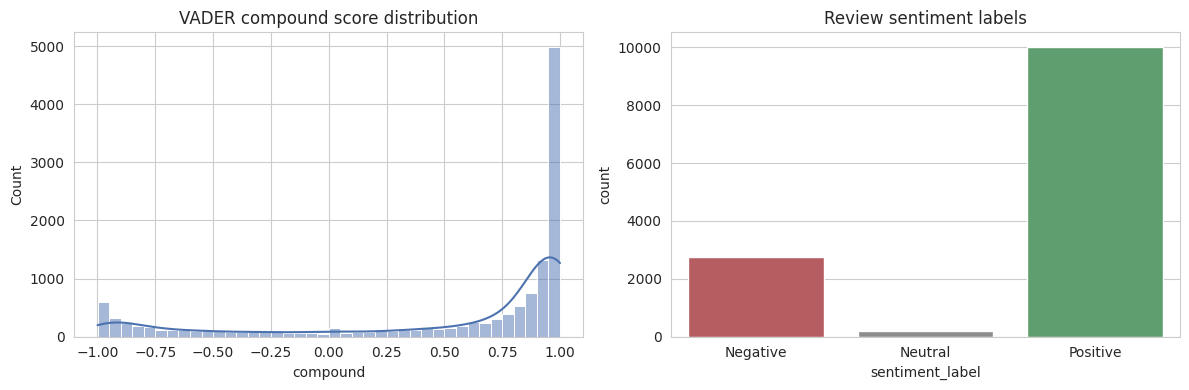

In [ ]:
sia = SentimentIntensityAnalyzer()
reviews['compound'] = reviews['clean_review'].apply(lambda t: sia.polarity_scores(t)['compound'])

def label(c):
    if c >= 0.05:  return 'Positive'
    if c <= -0.05: return 'Negative'
    return 'Neutral'
reviews['sentiment_label'] = reviews['compound'].apply(label)

print(reviews['sentiment_label'].value_counts())
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(reviews['compound'], bins=40, kde=True, ax=ax[0], color='#4C72B0')
ax[0].set_title('VADER compound score distribution')
sns.countplot(x='sentiment_label', data=reviews, order=['Negative', 'Neutral', 'Positive'], ax=ax[1],
              palette=['#C44E52', '#8C8C8C', '#55A868'])
ax[1].set_title('Review sentiment labels')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/sentiment_distribution.png', dpi=150); plt.show()

## 6. Movie-level sentiment aggregation

In [ ]:
agg = reviews.groupby('movie_id').agg(
    avg_sentiment=('compound', 'mean'),
    review_count=('compound', 'count'),
    negative_pct=('compound', lambda s: (s <= -0.05).mean() * 100),
    neutral_pct =('compound', lambda s: ((s > -0.05) & (s < 0.05)).mean() * 100),
    positive_pct=('compound', lambda s: (s >= 0.05).mean() * 100),
).reset_index()
print('Movies with real reviews:', len(agg))
agg.head()

Movies with real reviews: 3752


,movie_id,avg_sentiment,review_count,negative_pct,neutral_pct,positive_pct
0,11,0.929443,7,0.0,0.0,100.0
1,12,0.827825,4,0.0,0.0,100.0
2,13,0.767700,3,0.0,0.0,100.0
3,14,0.593233,3,0.0,0.0,100.0
4,15,0.935760,10,0.0,0.0,100.0


## 7. Merging datasets


In [ ]:
master = movies.merge(agg, left_on='id', right_on='movie_id', how='inner').drop(columns='movie_id')
print(f'Movies (cleaned)            : {len(movies)}')
print(f'Movies WITHOUT reviews      : {len(movies) - len(master)}  -> excluded from sentiment analysis & ML')
print(f'Movies WITH reviews (master): {len(master)}')
print('Missing values in sentiment columns:', master[['avg_sentiment', 'review_count']].isnull().sum().sum())

Movies (cleaned)            : 8643
Movies WITHOUT reviews      : 4895  -> excluded from sentiment analysis & ML
Movies WITH reviews (master): 3748
Missing values in sentiment columns: 0


## 8. Normalization
Votes & popularity heavily skewed (few blockbusters) → `log1p` first, then Min-Max scaling (0–1) for rating, votes, popularity, sentiment.

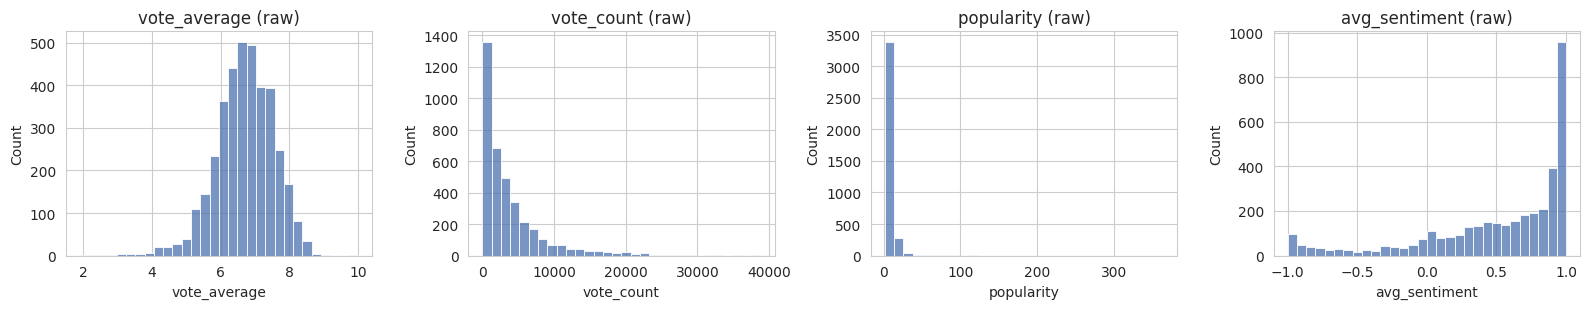

In [ ]:
fig, ax = plt.subplots(1, 4, figsize=(16, 3.2))
for a, c in zip(ax, ['vote_average', 'vote_count', 'popularity', 'avg_sentiment']):
    sns.histplot(master[c], bins=30, ax=a, color='#4C72B0'); a.set_title(c + ' (raw)')
plt.tight_layout(); plt.show()

In [ ]:
feat = pd.DataFrame({
    'rating'   : master['vote_average'],
    'votes'    : np.log1p(master['vote_count']),     # skew correction
    'popularity': np.log1p(master['popularity']),    # skew correction
    'sentiment': master['avg_sentiment'],
})
scaler = MinMaxScaler()
norm = pd.DataFrame(scaler.fit_transform(feat),
                    columns=['rating_norm', 'votes_norm', 'popularity_norm', 'sentiment_norm'],
                    index=master.index)
master = pd.concat([master, norm], axis=1)
master[norm.columns].describe().round(3)

,rating_norm,votes_norm,popularity_norm,sentiment_norm
count,3748.000,3748.000,3748.000,3748.000
mean,0.593,0.670,0.229,0.751
std,0.104,0.173,0.094,0.268
min,0.000,0.000,0.000,0.000
25%,0.531,0.574,0.165,0.624
50%,0.595,0.710,0.205,0.845
75%,0.666,0.789,0.265,0.968
max,1.000,1.000,1.000,1.000


## 9. Audience Interest Score
Weighted combination of the normalized features:

| Feature | Weight | Reason |
|---|---|---|
| Rating | 0.30 | Overall quality as judged by voters |
| Votes | 0.25 | Reach / how many people engaged |
| Popularity | 0.25 | Current attention |
| Sentiment | 0.20 | What reviewers actually wrote |

In [ ]:
WEIGHTS = {'rating_norm': 0.30, 'votes_norm': 0.25, 'popularity_norm': 0.25, 'sentiment_norm': 0.20}
master['audience_interest_score'] = sum(master[c] * w for c, w in WEIGHTS.items())
master['audience_interest_score'].describe().round(3)

,audience_interest_score
count,3748.000
mean,0.553
std,0.099
min,0.151
25%,0.498
50%,0.564
75%,0.620
max,0.817


## 10. Interest categorization
Quantile based (`qcut`) → balanced Low / Medium / High classes (≈ 33% each).

interest_category
Low       1250
Medium    1249
High      1249
Name: count, dtype: int64


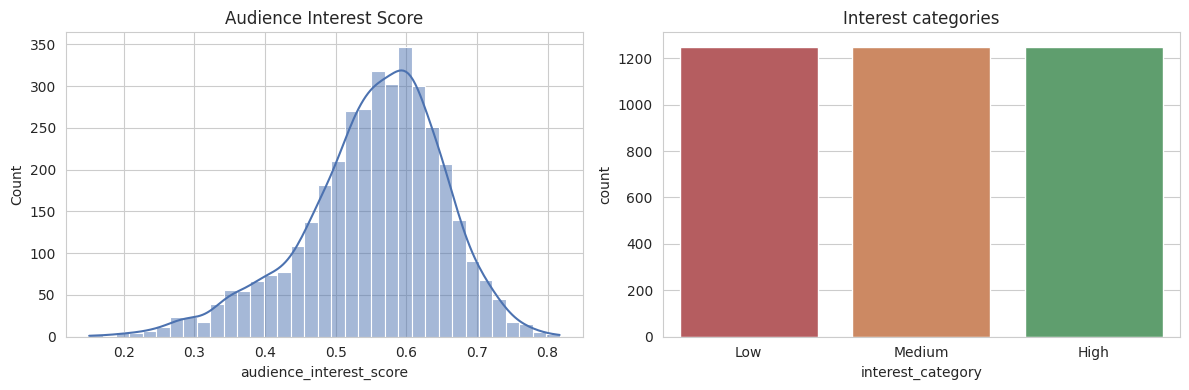

In [ ]:
master['interest_category'] = pd.qcut(master['audience_interest_score'], q=3, labels=['Low', 'Medium', 'High'])
print(master['interest_category'].value_counts())

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(master['audience_interest_score'], bins=35, kde=True, ax=ax[0], color='#4C72B0')
ax[0].set_title('Audience Interest Score')
sns.countplot(x='interest_category', data=master, order=['Low', 'Medium', 'High'], ax=ax[1],
              palette=['#C44E52', '#DD8452', '#55A868'])
ax[1].set_title('Interest categories')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/interest_distribution.png', dpi=150); plt.show()

## 11. Machine Learning
- **Features:** rating_norm, votes_norm, popularity_norm, sentiment_norm
- **Target:** interest_category (Low / Medium / High)
- **Split:** 80 / 20, stratified
- **Models:** Logistic Regression, Decision Tree, Random Forest (Decision Tree & Random Forest tuned with 5-fold GridSearchCV)

> **Note (limitation):** the target is derived from the same four features through a weighted formula, so high accuracy is expected (data leakage by design). The models are learning the scoring rule and category boundaries, not predicting independent real-world success.

In [ ]:
FEATURES = ['rating_norm', 'votes_norm', 'popularity_norm', 'sentiment_norm']
X = master[FEATURES]
y = master['interest_category'].astype(str)
CLASSES = ['Low', 'Medium', 'High']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print('Train:', X_train.shape, ' Test:', X_test.shape)

Train: (2998, 4)  Test: (750, 4)


In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

models = {
    'Logistic Regression': LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    'Decision Tree': GridSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE),
                                  {'max_depth': [4, 6, 8, 10, 12, 15], 'min_samples_leaf': [1, 3, 5, 10]},
                                  cv=cv, scoring='accuracy', n_jobs=-1),
    'Random Forest': GridSearchCV(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
                                  {'n_estimators': [200, 400], 'max_depth': [10, 15, None]},
                                  cv=cv, scoring='accuracy', n_jobs=-1),
}

results, preds, fitted = [], {}, {}
for name, model in models.items():
    model.fit(X_train, y_train)
    best = model.best_estimator_ if hasattr(model, 'best_estimator_') else model
    if hasattr(model, 'best_params_'):
        print(f'{name} best params:', model.best_params_)
    y_pred = best.predict(X_test)
    cv_acc = cross_val_score(best, X_train, y_train, cv=cv, scoring='accuracy').mean()
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision (macro)': precision_score(y_test, y_pred, average='macro'),
        'Recall (macro)': recall_score(y_test, y_pred, average='macro'),
        'F1 (macro)': f1_score(y_test, y_pred, average='macro'),
        'CV Accuracy (5-fold)': cv_acc,
    })
    preds[name], fitted[name] = y_pred, best

metrics = pd.DataFrame(results).set_index('Model').round(4)
metrics

Decision Tree best params: {'max_depth': 15, 'min_samples_leaf': 1}
Random Forest best params: {'max_depth': 10, 'n_estimators': 400}


,Accuracy,Precision (macro),Recall (macro),F1 (macro),CV Accuracy (5-fold)
Model,,,,,
Logistic Regression,0.9640,0.9642,0.9640,0.9641,0.9506
Decision Tree,0.8827,0.8833,0.8827,0.8829,0.8843
Random Forest,0.9467,0.9480,0.9467,0.9469,0.9390


Logistic Regression
              precision    recall  f1-score   support

         Low      0.971     0.952     0.962       250
      Medium      0.937     0.956     0.947       250
        High      0.984     0.984     0.984       250

    accuracy                          0.964       750
   macro avg      0.964     0.964     0.964       750
weighted avg      0.964     0.964     0.964       750

Decision Tree
              precision    recall  f1-score   support

         Low      0.942     0.916     0.929       250
      Medium      0.825     0.828     0.826       250
        High      0.883     0.904     0.893       250

    accuracy                          0.883       750
   macro avg      0.883     0.883     0.883       750
weighted avg      0.883     0.883     0.883       750

Random Forest
              precision    recall  f1-score   support

         Low      0.980     0.968     0.974       250
      Medium      0.898     0.948     0.922       250
        High      0.967    

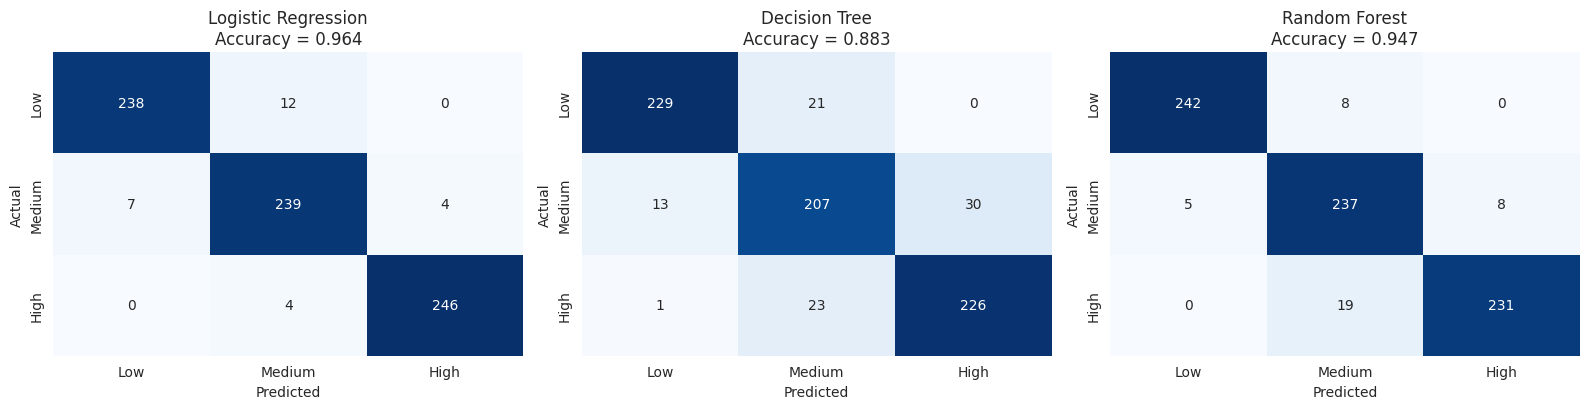

In [ ]:
for name, y_pred in preds.items():
    print('=' * 60); print(name)
    print(classification_report(y_test, y_pred, labels=CLASSES, digits=3))

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
for a, (name, y_pred) in zip(ax, preds.items()):
    cm = confusion_matrix(y_test, y_pred, labels=CLASSES)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASSES, yticklabels=CLASSES, ax=a, cbar=False)
    a.set_title(f'{name}\nAccuracy = {accuracy_score(y_test, y_pred):.3f}')
    a.set_xlabel('Predicted'); a.set_ylabel('Actual')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/confusion_matrices.png', dpi=150); plt.show()

In [ ]:
# Feature importance: LR -> mean |coefficient|, DT / RF -> feature_importances_
lr = fitted['Logistic Regression']
imp = pd.DataFrame({
    'Logistic Regression': np.abs(lr.coef_).mean(axis=0),
    'Decision Tree': fitted['Decision Tree'].feature_importances_,
    'Random Forest': fitted['Random Forest'].feature_importances_,
}, index=FEATURES)
imp = imp / imp.sum()                       # scale each model to sum = 1 for comparison
imp.round(4)

,Logistic Regression,Decision Tree,Random Forest
rating_norm,0.2787,0.2214,0.2395
votes_norm,0.2868,0.3165,0.3191
popularity_norm,0.2185,0.1635,0.1352
sentiment_norm,0.2159,0.2986,0.3063


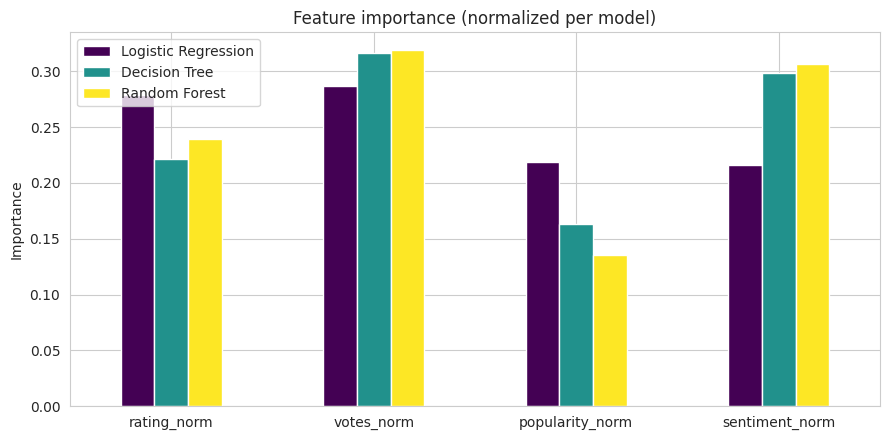

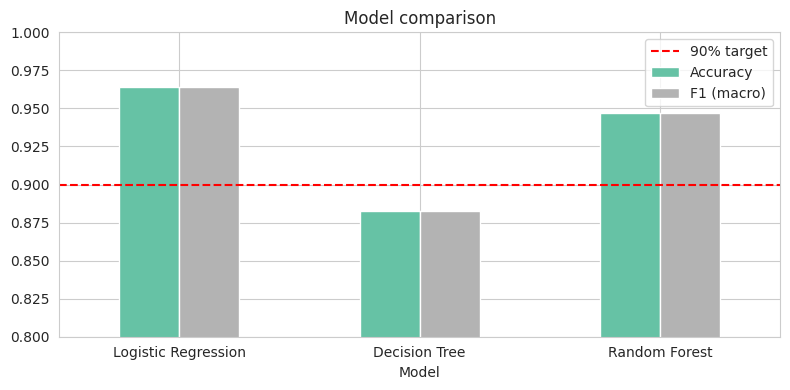

Best model: Logistic Regression  |  Accuracy = 96.40%


In [ ]:
imp.plot(kind='bar', figsize=(9, 4.5), colormap='viridis')
plt.title('Feature importance (normalized per model)'); plt.ylabel('Importance'); plt.xticks(rotation=0)
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/feature_importance.png', dpi=150); plt.show()

metrics[['Accuracy', 'F1 (macro)']].plot(kind='bar', figsize=(8, 4), ylim=(0.8, 1.0), colormap='Set2')
plt.axhline(0.90, color='red', ls='--', label='90% target'); plt.legend(); plt.xticks(rotation=0)
plt.title('Model comparison'); plt.tight_layout()
plt.savefig(f'{OUT_DIR}/model_comparison.png', dpi=150); plt.show()

best_name = metrics['Accuracy'].idxmax()
print(f'Best model: {best_name}  |  Accuracy = {metrics.loc[best_name, "Accuracy"]:.2%}')

## 12. Exporting final outputs

In [ ]:
# Master dataset (movie metadata + aggregated sentiment + normalized features + score + category)
master_cols = ['id', 'title', 'release_date', 'genres', 'original_language', 'runtime', 'budget', 'revenue',
               'vote_average', 'vote_count', 'popularity',
               'review_count', 'avg_sentiment', 'negative_pct', 'neutral_pct', 'positive_pct',
               'rating_norm', 'votes_norm', 'popularity_norm', 'sentiment_norm',
               'audience_interest_score', 'interest_category']
master[master_cols].to_csv(f'{OUT_DIR}/final_master_dataset.csv', index=False)

# Review-level sentiment
reviews[['id', 'movie_id', 'compound', 'sentiment_label']].rename(columns={'id': 'review_id'}) \
    .to_csv(f'{OUT_DIR}/review_sentiment_scores.csv', index=False)

# ML outputs
metrics.to_csv(f'{OUT_DIR}/model_metrics.csv')
imp.to_csv(f'{OUT_DIR}/feature_importance.csv')
for name, y_pred in preds.items():
    cm = pd.DataFrame(confusion_matrix(y_test, y_pred, labels=CLASSES),
                      index=[f'actual_{c}' for c in CLASSES], columns=[f'pred_{c}' for c in CLASSES])
    cm.to_csv(f"{OUT_DIR}/confusion_matrix_{name.replace(' ', '_').lower()}.csv")
    pd.DataFrame(classification_report(y_test, y_pred, labels=CLASSES, output_dict=True)).T \
        .to_csv(f"{OUT_DIR}/classification_report_{name.replace(' ', '_').lower()}.csv")
pd.DataFrame({'actual': y_test.values, **{n: p for n, p in preds.items()}}, index=y_test.index) \
    .to_csv(f'{OUT_DIR}/test_predictions.csv')

# ZIP everything
zip_name = 'movie_audience_interest_outputs.zip'
with zipfile.ZipFile(zip_name, 'w', zipfile.ZIP_DEFLATED) as z:
    for f in sorted(os.listdir(OUT_DIR)):
        z.write(os.path.join(OUT_DIR, f), arcname=f)
print('ZIP created:', zip_name)
print(sorted(os.listdir(OUT_DIR)))

try:
    from google.colab import files
    files.download(zip_name)
except ImportError:
    pass

ZIP created: movie_audience_interest_outputs.zip
['classification_report_decision_tree.csv', 'classification_report_logistic_regression.csv', 'classification_report_random_forest.csv', 'confusion_matrices.png', 'confusion_matrix_decision_tree.csv', 'confusion_matrix_logistic_regression.csv', 'confusion_matrix_random_forest.csv', 'feature_importance.csv', 'feature_importance.png', 'final_master_dataset.csv', 'interest_distribution.png', 'model_comparison.png', 'model_metrics.csv', 'review_sentiment_scores.csv', 'sentiment_distribution.png', 'test_predictions.csv']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>